# FinGuard Executive Walkthrough

**Executive notebook · Malaysian consumer-credit risk case study**

本 notebook 只读取已审核的轻量 CSV 汇总及 `reports/figures/` 中已保存的 PNG；不会读取原始 parquet、序列化模型或重新拟合模型。所有图表均嵌入 notebook 输出，便于 GitHub 浏览。模拟利润是设定假设下的结果，不代表因果收益或未来实际收益。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / 'data' / 'powerbi').is_dir(), f'Run this notebook from project root: {ROOT}'
CSV_FILES = {
    'selected': 'data/processed/stage2_selected_features.csv',
    'points': 'data/processed/scorecard_points_table.csv',
    'drift': 'data/processed/stage5_psi_csi_summary.csv',
    'pbi01': 'data/powerbi/pbi_01_temporal_cohort_monitoring.csv',
    'pbi02': 'data/powerbi/pbi_02_cutoff_tradeoff_curve.csv',
    'pbi03': 'data/powerbi/pbi_03_portfolio_concentration.csv',
    'pbi04': 'data/powerbi/pbi_04_stress_scenarios.csv',
    'pbi05': 'data/powerbi/pbi_05_psi_csi_and_fairness.csv',
    'pbi06': 'data/powerbi/pbi_06_delinquency_migration.csv',
}
data = {key: pd.read_csv(ROOT / rel) for key, rel in CSV_FILES.items()}
print(f'Loaded {len(data)} approved summary CSVs; no model fitting or raw-data access.')

def show_saved_figure(filename, caption=None):
    path = ROOT / 'reports' / 'figures' / filename
    assert path.is_file(), f'Missing saved figure: {path}'
    if caption:
        display(Markdown(f'**{caption}**'))
    display(Image(filename=str(path)))

Loaded 9 approved summary CSVs; no model fitting or raw-data access.


## 1. Temporal Split & Portfolio Overview

按时间划分避免将后续时期的信息带入模型拟合。`OOT_Valid` 用于冻结模型评估；在 Stage 5 中曾用于拟合明确披露的 recalibration/cutoff，之后才前向应用到 `OOT_Monitor`。`OOT_Monitor` 的标签只用于事后监控评估。

| Split | Weeks | Applications | Observed bad rate |
|---|---:|---:|---:|
| `Train_Dev` | 0–64 | 1,292,350 | 3.3154% |
| `OOT_Valid` | 65–77 | 82,602 | 2.3401% |
| `OOT_Monitor` | 78–91 | 151,707 | 2.1192% |
| **Portfolio** | **0–91** | **1,526,659** | **3.1437%** |

,Split,Weeks,Applications,Bad_Rate_Pct
0,Train_Dev,0–64,1292350,3.3154
1,OOT_Valid,65–77,82602,2.3401
2,OOT_Monitor,78–91,151707,2.1192
3,Portfolio,0–91,1526659,3.1437


,Grain,Period,Period_Order,Split,Model,Risk_Tier,Applications,Bads,Approvals,Actual_Bad_Rate_Pct,Raw_PD_Pct,Recalibrated_PD_Pct,Avg_Recommended_Exposure,Recommended_Volume,KS,Gini
1100,Monthly,202006,202006,OOT_Monitor,Challenger LightGBM M4,Tier A: Super Prime,474,2.0,449.0,0.421941,0.754538,0.572580,51417.745618,2.308657e+07,0.345339,-0.122881
1101,Monthly,202006,202006,OOT_Monitor,Challenger LightGBM M4,Tier B: Prime,335,0.0,310.0,0.000000,1.858530,1.413913,48731.888142,1.510689e+07,NaN,NaN
1102,Monthly,202006,202006,OOT_Monitor,Challenger LightGBM M4,Tier C: Standard,308,3.0,291.0,0.974026,3.697400,2.826018,39563.936875,1.151311e+07,0.267760,-0.066667
1103,Monthly,202006,202006,OOT_Monitor,Challenger LightGBM M4,Tier D: High Risk,202,7.0,70.0,3.465347,6.715237,5.171569,32974.669552,2.308227e+06,0.241026,0.002198
1104,Monthly,202006,202006,OOT_Monitor,Challenger LightGBM M4,Tier E: Decline,148,28.0,0.0,18.918919,14.122475,11.139828,NaN,0.000000e+00,0.411905,0.411905
1110,Monthly,202006,202006,OOT_Monitor,Champion Scorecard,Tier A: Super Prime,502,3.0,484.0,0.597610,0.883320,0.677061,53624.084866,2.595406e+07,0.570474,0.444222
1111,Monthly,202006,202006,OOT_Monitor,Champion Scorecard,Tier B: Prime,410,3.0,390.0,0.731707,1.909077,1.466843,45423.665111,1.771523e+07,0.432432,0.343161
1112,Monthly,202006,202006,OOT_Monitor,Champion Scorecard,Tier C: Standard,315,9.0,205.0,2.857143,3.614977,2.789296,45228.382033,9.271818e+06,0.323529,0.213508
1113,Monthly,202006,202006,OOT_Monitor,Champion Scorecard,Tier D: High Risk,148,10.0,0.0,6.756757,6.874335,5.345987,NaN,0.000000e+00,0.326087,-0.324638
1114,Monthly,202006,202006,OOT_Monitor,Champion Scorecard,Tier E: Decline,92,15.0,0.0,16.304348,14.462845,11.523472,NaN,0.000000e+00,0.387879,0.421645


**Saved temporal cohort trend**

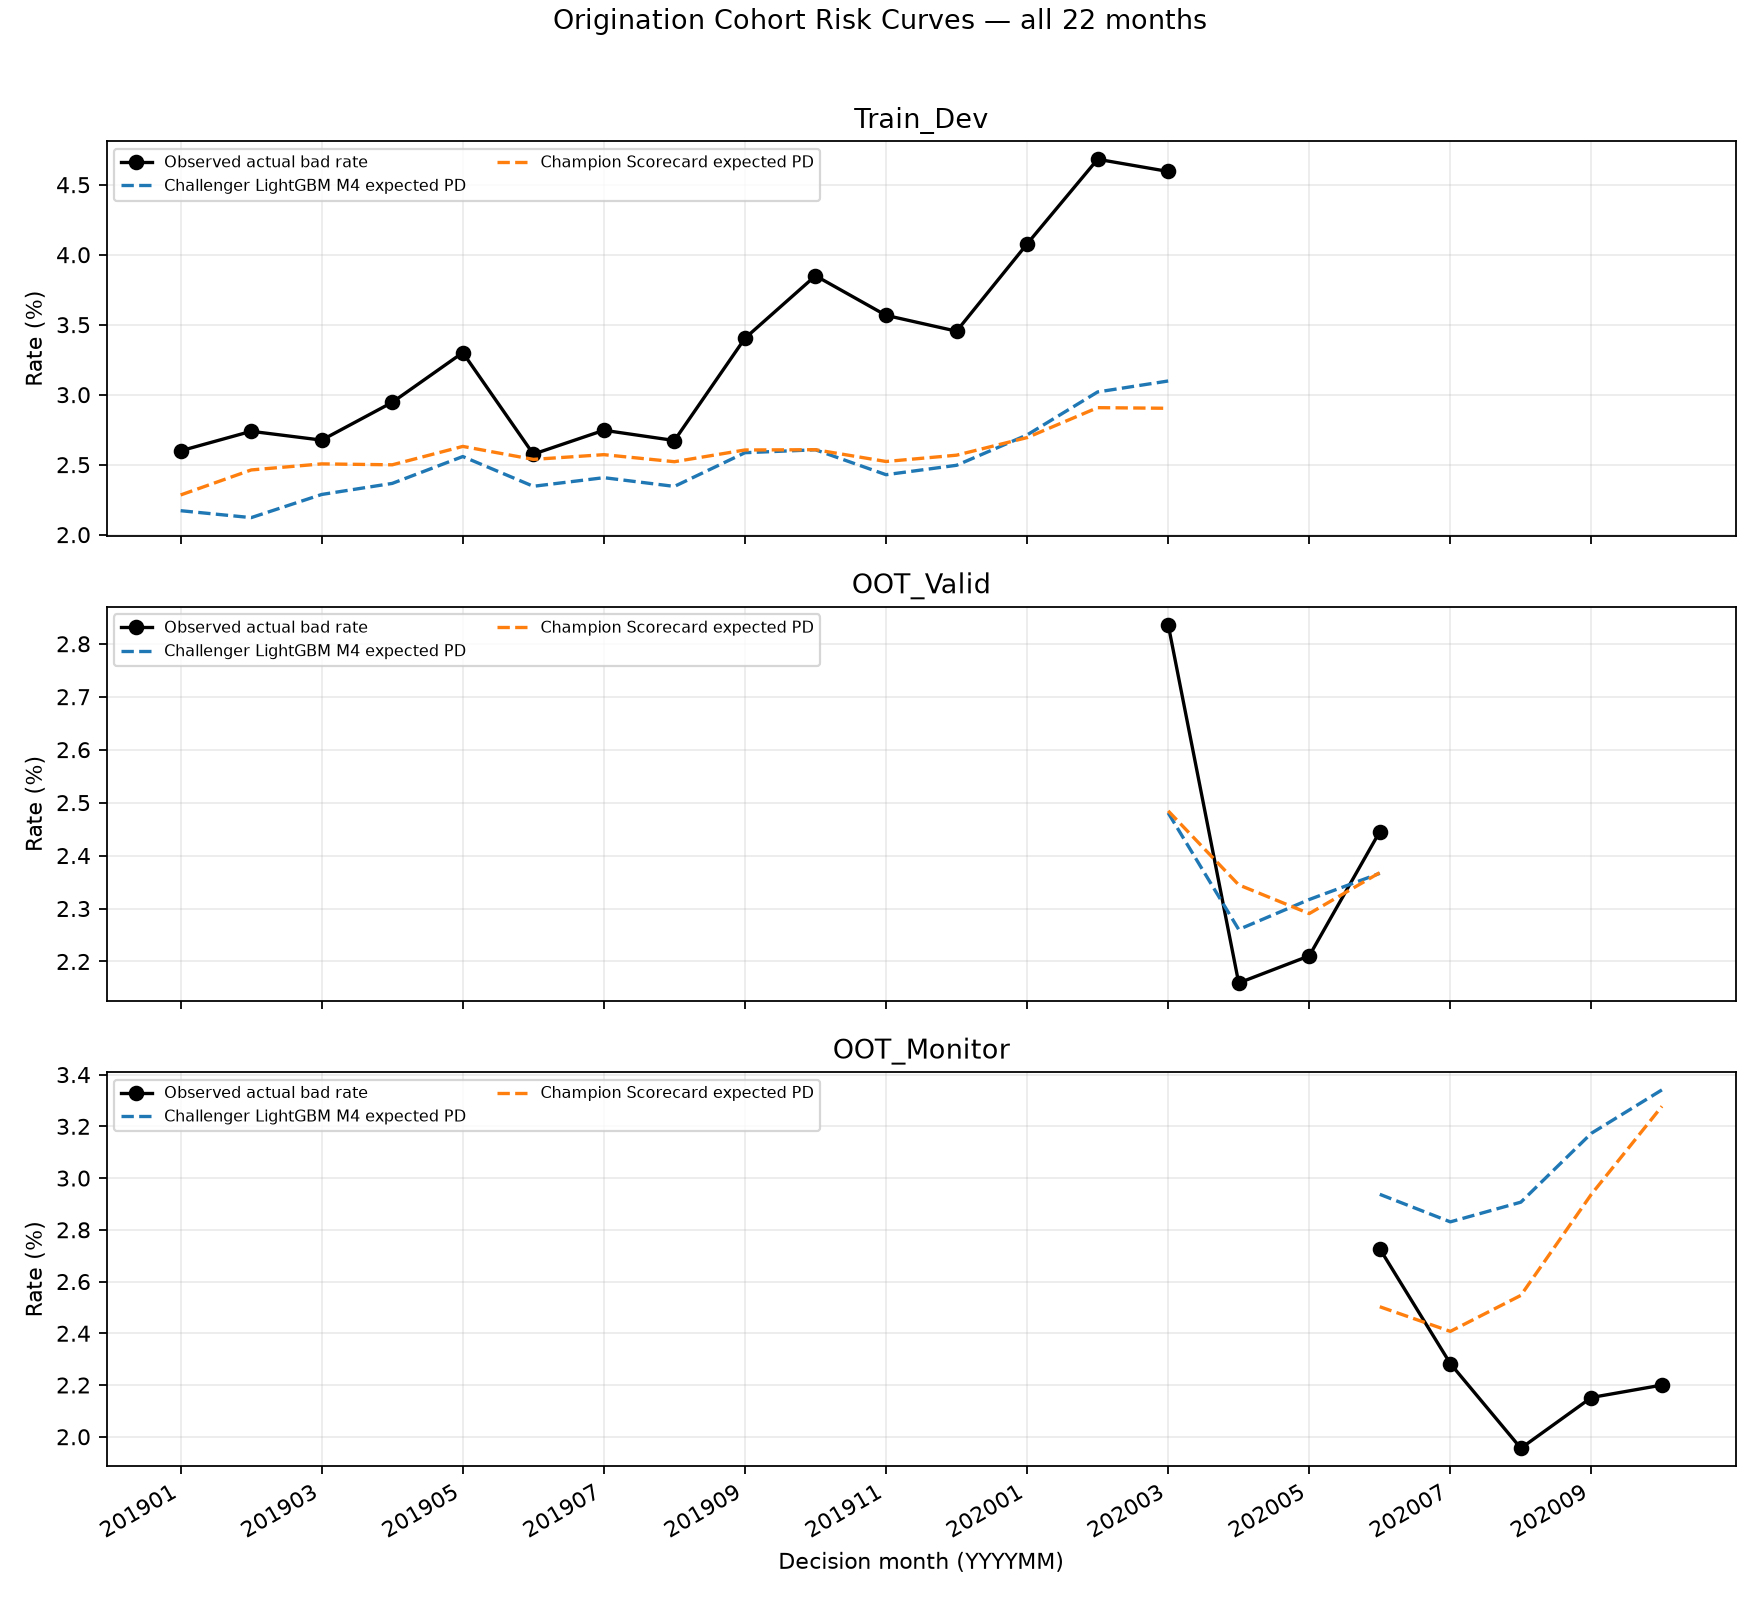

In [2]:
cohort = pd.DataFrame([
    {'Split': 'Train_Dev', 'Weeks': '0–64', 'Applications': 1292350, 'Bad_Rate_Pct': 3.3154},
    {'Split': 'OOT_Valid', 'Weeks': '65–77', 'Applications': 82602, 'Bad_Rate_Pct': 2.3401},
    {'Split': 'OOT_Monitor', 'Weeks': '78–91', 'Applications': 151707, 'Bad_Rate_Pct': 2.1192},
    {'Split': 'Portfolio', 'Weeks': '0–91', 'Applications': 1526659, 'Bad_Rate_Pct': 3.1437},
])
display(cohort)
display(data['pbi01'].query("Grain == 'Monthly' and Split == 'OOT_Monitor'").head(10))
show_saved_figure('stage6_cohort_vintage_trend.png', 'Saved temporal cohort trend')

## 2. Champion 19-Feature WOE Scorecard & Sample Points Card

Champion 是具可解释性的 WOE Logistic scorecard。Stage 2 的 selected list 与最终 Champion 变量集并不完全相同；此处并列展示筛选清单和已导出的点数表，不把候选数误当最终特征数。计分方向为分数越高、风险越低。

In [3]:
selected = data['selected']
points = data['points']
champion = points[['Feature', 'Group', 'Coef']].drop_duplicates('Feature').copy()
champion['Coef'] = pd.to_numeric(champion['Coef'], errors='coerce')
display(Markdown(f'**Champion retained features:** {champion.Feature.nunique()} · **Stage 2 selected rows:** {len(selected)}'))
display(champion.sort_values('Coef').head(12).reset_index(drop=True))
display(Markdown('**Sample scorecard points (saved OptimalBinning-derived bins):**'))
display(points[['Feature', 'Bin Range', 'WOE', 'Coef', 'Bin Points']].head(14).round(4))

**Champion retained features:** 19 · **Stage 2 selected rows:** 23

,Feature,Group,Coef
0,person_education_level,Group_3_Application_Demographic,-1.076892
1,person_employment_years,Group_3_Application_Demographic,-1.017382
2,person_income_type,Group_3_Application_Demographic,-0.947572
3,person_family_status,Group_3_Application_Demographic,-0.841867
4,prev_appl_avg_tenor,Group_2_Repayment_Behaviour,-0.715468
5,static_cnt_pmts_months_24m,Group_2_Repayment_Behaviour,-0.636374
6,static_last_rejected_amount,Group_1_Traditional_Credit,-0.623549
7,static_num_inst_paid_early,Group_2_Repayment_Behaviour,-0.619562
8,bureau_active_max_dpd,Group_1_Traditional_Credit,-0.595027
9,bureau_queries_120d,Group_1_Traditional_Credit,-0.459382


**Sample scorecard points (saved OptimalBinning-derived bins):**

,Feature,Bin Range,WOE,Coef,Bin Points
0,static_avg_dpd_tol_closure24m,"(-inf, 0.50)",0.4730,-0.2410,8.2217
1,static_avg_dpd_tol_closure24m,"[0.50, 1.50)",-0.3000,-0.2410,-5.2153
2,static_avg_dpd_tol_closure24m,"[1.50, 5.50)",-0.8168,-0.2410,-14.1979
3,static_avg_dpd_tol_closure24m,"[5.50, inf)",-1.2372,-0.2410,-21.5049
4,static_avg_dpd_tol_closure24m,Special,0.0000,-0.2410,0.0000
5,static_avg_dpd_tol_closure24m,Missing,0.0940,-0.2410,1.6341
6,bureau_active_max_dpd,"(-inf, 0.50)",0.3077,-0.5950,13.2065
7,bureau_active_max_dpd,"[0.50, 3.50)",-0.0450,-0.5950,-1.9321
8,bureau_active_max_dpd,"[3.50, 10.50)",-0.3427,-0.5950,-14.7096
9,bureau_active_max_dpd,"[10.50, 27.50)",-0.5441,-0.5950,-23.3550


## 3. Challenger LightGBM M4, 4-Group Ablation Lift & SHAP Drivers

M4 是 73-feature monotonic LightGBM。Ablation 表按既定分组逐步加入特征；这是本数据和分组顺序下的增量比较，不是因果特征价值。Group 4 中部分代理变量触发 internal PSI override，生产使用前需重做稳定性审查。SHAP 图为已保存的 OOT_Valid 评估样本解释图，不在 notebook 中重新计算。

,Model,Groups,Features,Dev_Calib_KS,OOT_Valid_KS
0,M1,Group 1,13,0.3113,0.3236
1,M2,Groups 1 + 2,45,0.4058,0.4290
2,M3,Groups 1 + 2 + 3,50,0.4248,0.4671
3,M4,Groups 1 + 2 + 3 + 4 / Affordability,73,0.4604,0.4929


**Saved SHAP global importance (M4)**

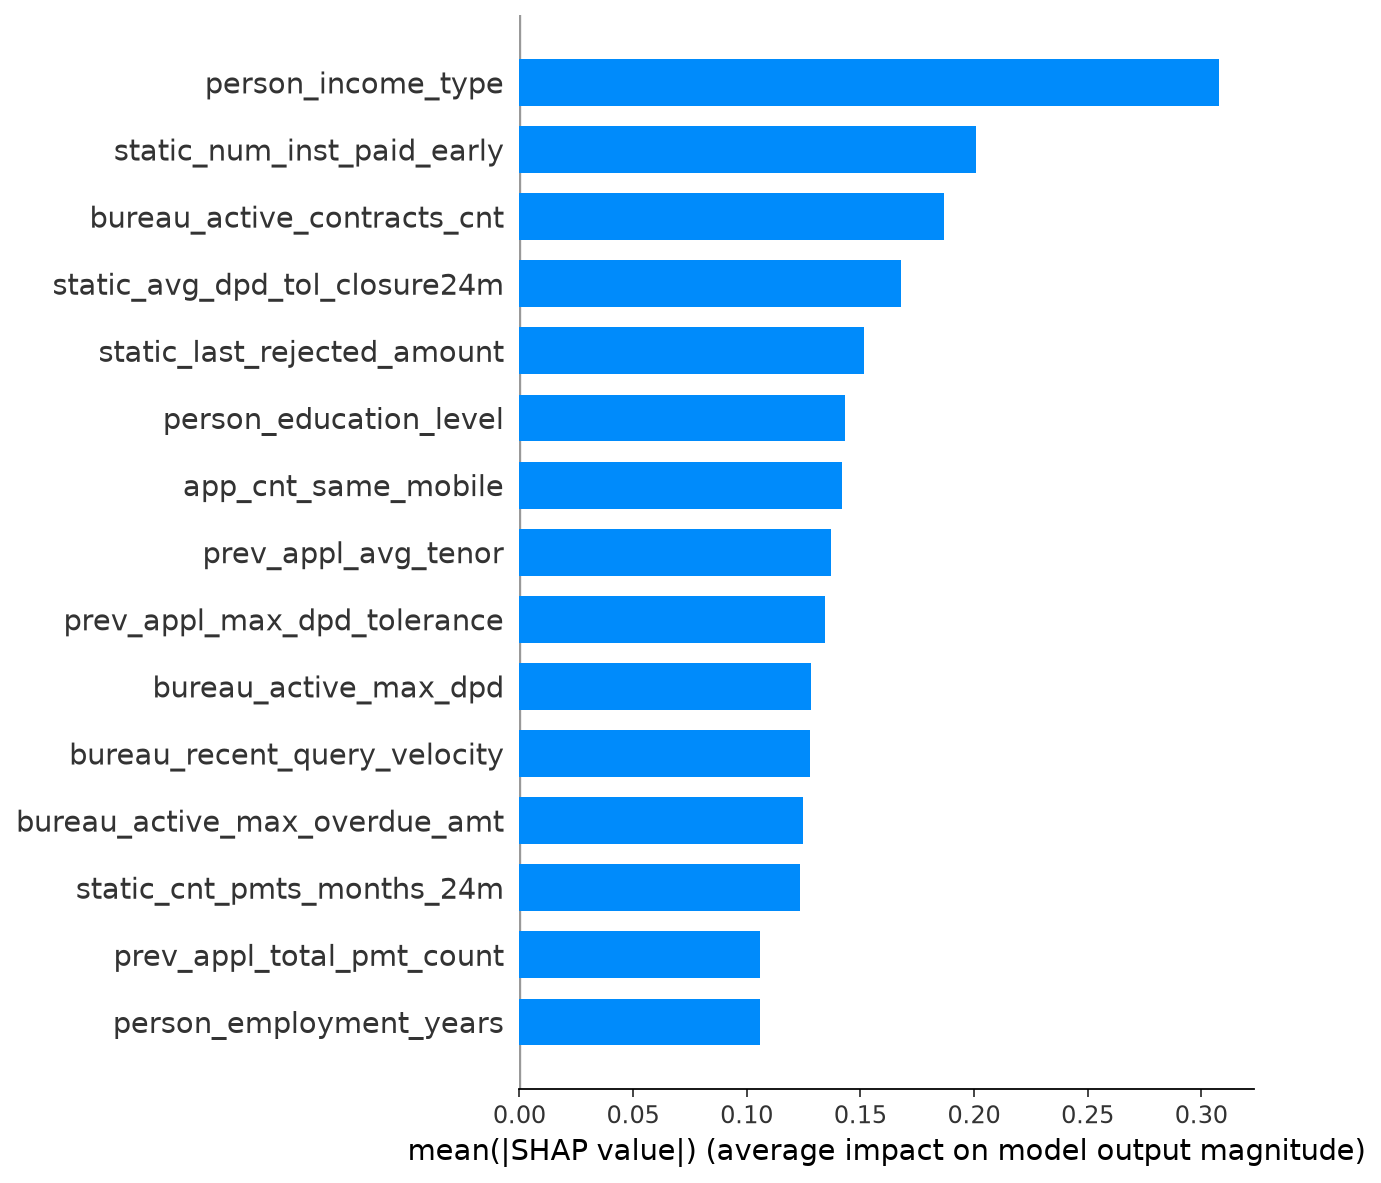

**Saved SHAP distribution (M4)**

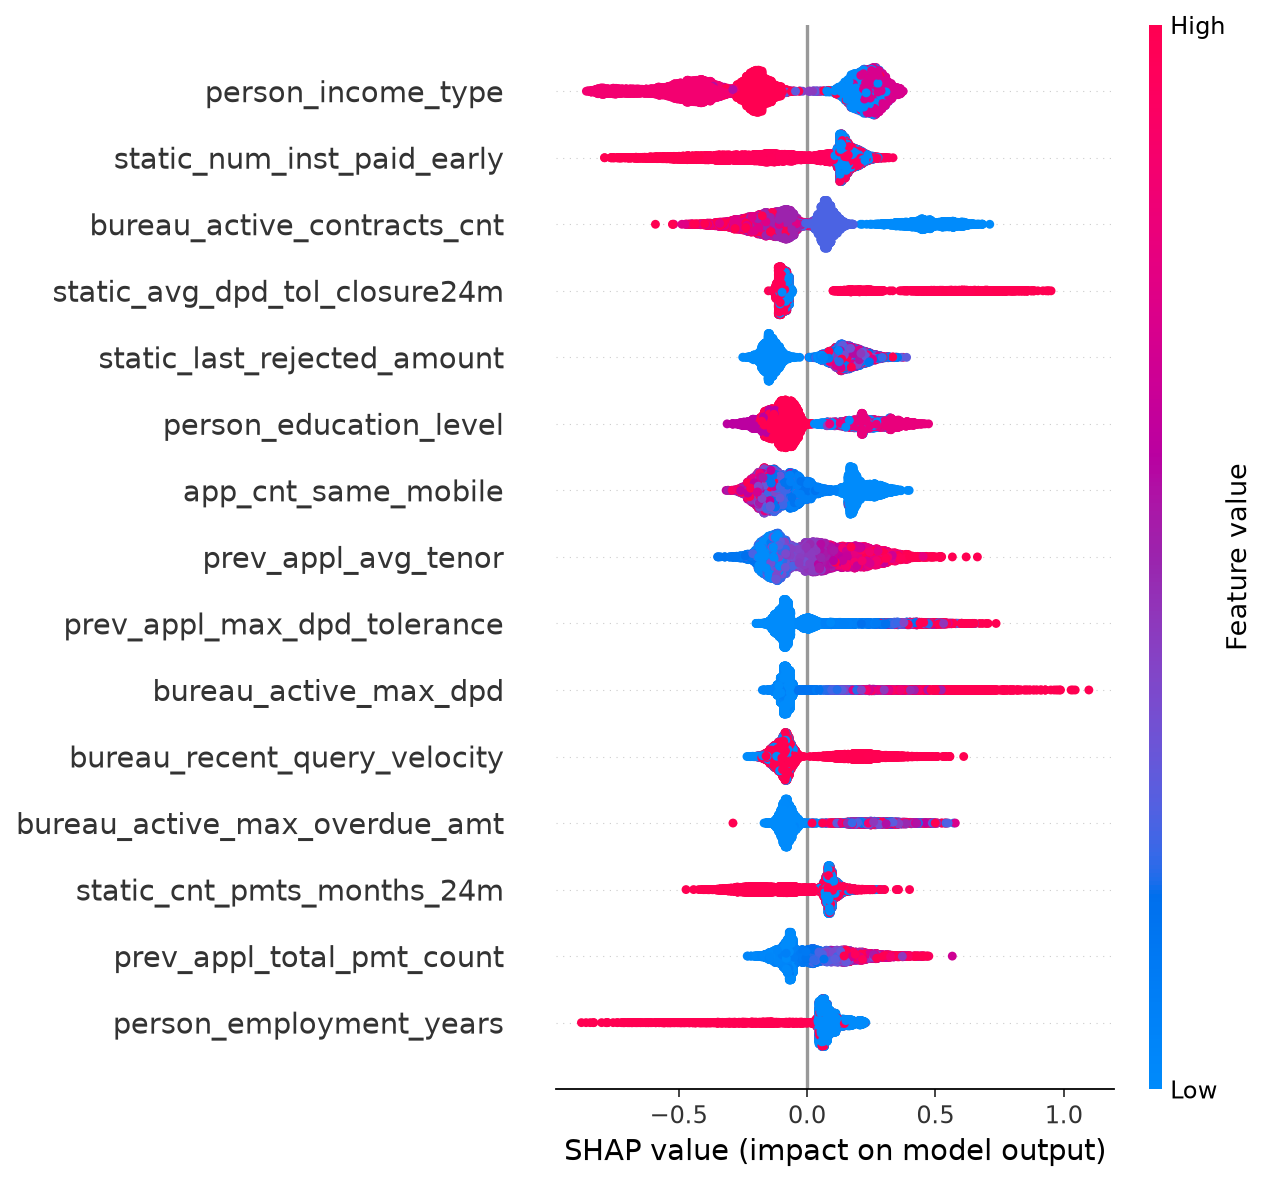

In [4]:
ablation = pd.DataFrame([
    {'Model': 'M1', 'Groups': 'Group 1', 'Features': 13, 'Dev_Calib_KS': 0.3113, 'OOT_Valid_KS': 0.3236},
    {'Model': 'M2', 'Groups': 'Groups 1 + 2', 'Features': 45, 'Dev_Calib_KS': 0.4058, 'OOT_Valid_KS': 0.4290},
    {'Model': 'M3', 'Groups': 'Groups 1 + 2 + 3', 'Features': 50, 'Dev_Calib_KS': 0.4248, 'OOT_Valid_KS': 0.4671},
    {'Model': 'M4', 'Groups': 'Groups 1 + 2 + 3 + 4 / Affordability', 'Features': 73, 'Dev_Calib_KS': 0.4604, 'OOT_Valid_KS': 0.4929},
])
display(ablation)
show_saved_figure('shap_summary_bar.png', 'Saved SHAP global importance (M4)')
show_saved_figure('shap_beeswarm.png', 'Saved SHAP distribution (M4)')

## 4. Driver-Based Credit Limit Engine & Blind OOT_Monitor Iso-Risk Breakthrough

额度规则为 `min(L_requested, L_risk_behavior, L_affordability)`。Stage 4 的 DSR、定价、成本与 LGD 数字是政策/经济模拟假设。下表是已冻结政策在 `OOT_Monitor` 的前向回放；利润为 simulated ENP，并非因果增量或已实现账面收益。

,Model,Approval_Rate_Pct,Approved_Cases,Observed_Bad_Rate_Pct,Simulated_ENP_M
0,Champion Scorecard,70.7970,107404,0.9990,132.180254
1,Challenger LightGBM M4,75.1587,114021,0.8832,140.125997


**Forward comparison:** +6,617 approvals · −0.1158 percentage points observed bad rate · +7.945743M simulated ENP.

,Model,Risk_Tier,Income_Type,Ticket_Band,Tenor_Band,Approved_Count,Total_Recommended_Volume,Observed_Bad_Rate_Pct
2918,Champion Scorecard,Tier A: Super Prime,RETIRED_PENSIONER,100k+,13-24m,2578,3.024729e+08,0.581846
1020,Challenger LightGBM M4,Tier A: Super Prime,RETIRED_PENSIONER,100k+,13-24m,1979,2.298301e+08,0.252653
1038,Challenger LightGBM M4,Tier A: Super Prime,RETIRED_PENSIONER,20k-50k,7-12m,4332,1.378504e+08,0.277008
2919,Champion Scorecard,Tier A: Super Prime,RETIRED_PENSIONER,100k+,13-24m,1406,1.342245e+08,1.066856
2936,Champion Scorecard,Tier A: Super Prime,RETIRED_PENSIONER,20k-50k,7-12m,3988,1.277284e+08,0.325978
2948,Champion Scorecard,Tier A: Super Prime,RETIRED_PENSIONER,50k-100k,7-12m,1877,1.223550e+08,0.159830
1050,Challenger LightGBM M4,Tier A: Super Prime,RETIRED_PENSIONER,50k-100k,7-12m,1837,1.199740e+08,0.163310
1311,Challenger LightGBM M4,Tier B: Prime,RETIRED_PENSIONER,100k+,13-24m,1320,1.174964e+08,1.363636
2942,Champion Scorecard,Tier A: Super Prime,RETIRED_PENSIONER,50k-100k,13-24m,1520,1.072483e+08,0.723684
1044,Challenger LightGBM M4,Tier A: Super Prime,RETIRED_PENSIONER,50k-100k,13-24m,1341,9.458263e+07,0.372856


**Saved decision trade-off**

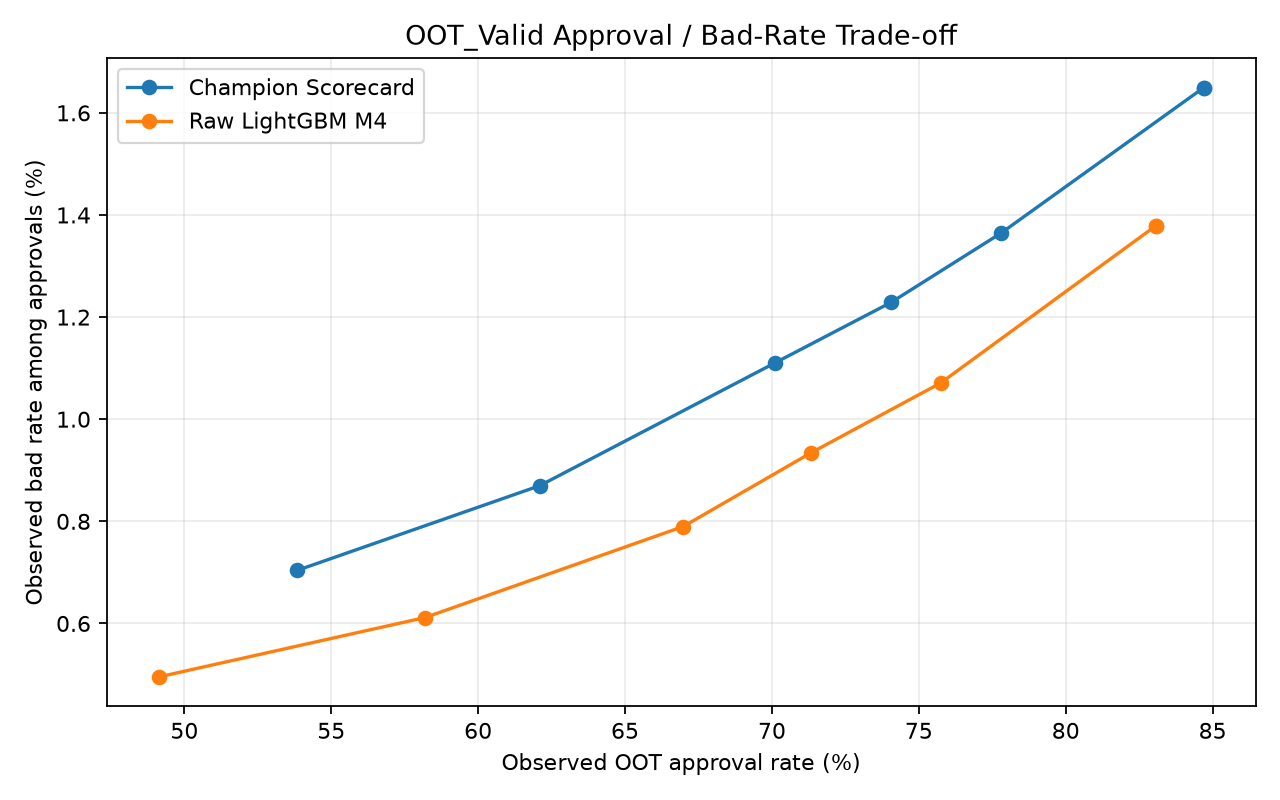

**Saved expected net profit comparison**

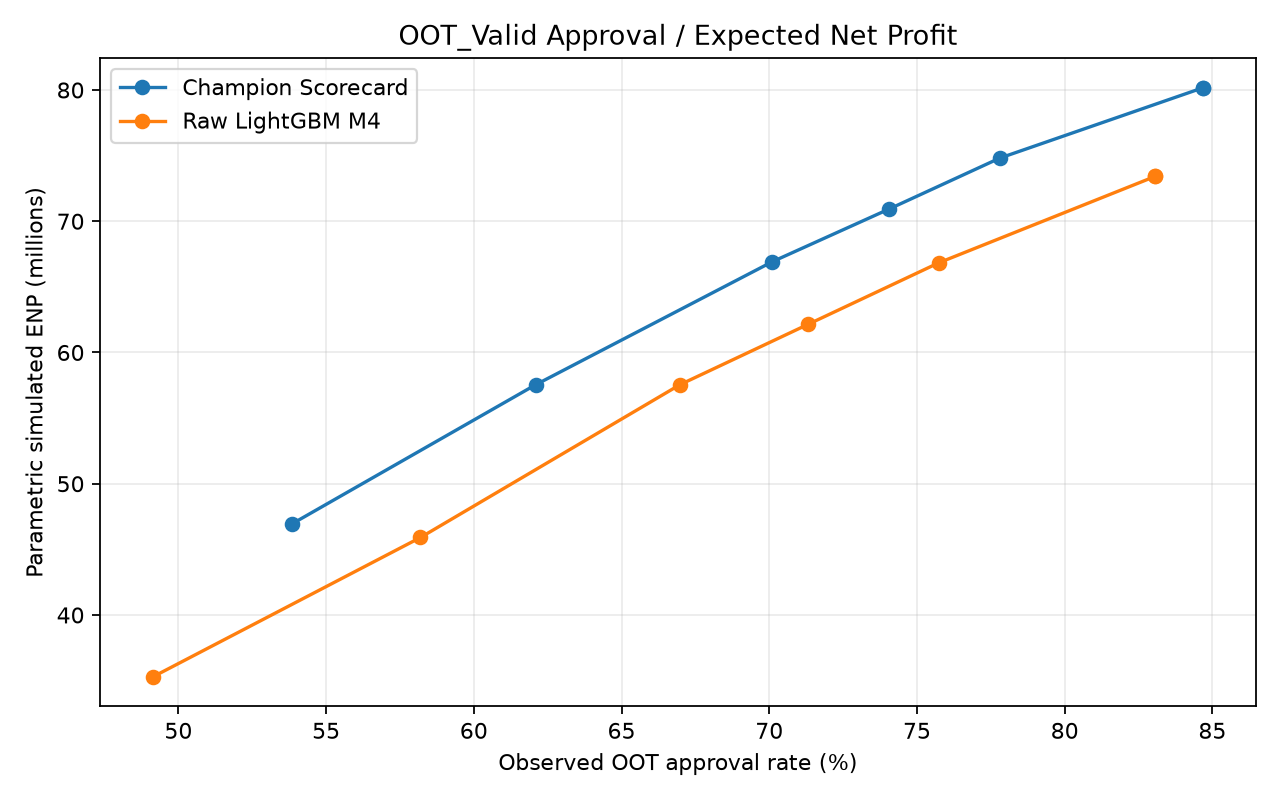

In [5]:
iso_risk = pd.DataFrame([
    {'Model': 'Champion Scorecard', 'Approval_Rate_Pct': 70.7970, 'Approved_Cases': 107404, 'Observed_Bad_Rate_Pct': 0.9990, 'Simulated_ENP_M': 132.1802538},
    {'Model': 'Challenger LightGBM M4', 'Approval_Rate_Pct': 75.1587, 'Approved_Cases': 114021, 'Observed_Bad_Rate_Pct': 0.8832, 'Simulated_ENP_M': 140.1259970},
])
display(iso_risk)
display(Markdown('**Forward comparison:** +6,617 approvals · −0.1158 percentage points observed bad rate · +7.945743M simulated ENP.'))
mode = data['pbi03'].query("Mode == 'Iso-Risk'")
if not mode.empty:
    segment_view = mode.sort_values('Total_Recommended_Volume', ascending=False)
    display(segment_view[['Model', 'Risk_Tier', 'Income_Type', 'Ticket_Band', 'Tenor_Band', 'Approved_Count', 'Total_Recommended_Volume', 'Observed_Bad_Rate_Pct']].head(12))
show_saved_figure('stage4_approval_bad_rate.png', 'Saved decision trade-off')
show_saved_figure('stage4_expected_net_profit.png', 'Saved expected net profit comparison')

## 5. PSI/CSI Drift Governance, Zero-Leakage Recalibration, Fair Lending AIR & S1–S4 Stress Resilience

Stage 5 recalibration and cutoffs were fit on `OOT_Valid` and then frozen for forward `OOT_Monitor` application. The monitor window was not used to fit calibrators or choose policy thresholds. Low aggregate score PSI does not rule out feature-level CSI drift. AIR is a diagnostic and the gender field is overwhelmingly unknown; neither is a standalone legal finding.

Stage 6 uses observed prior-contract DPD severity because the available prior-application table has no monthly snapshots. Stress “realized” values are scenario proxies, not observed downturn outcomes.

**Largest saved PSI/CSI observations:**

,Type,Feature / Score,Comparison,PSI / CSI,Reference Status
55,Feature CSI,has_tax_registry_record,Train_Dev vs OOT_Monitor,1.306385,Major shift
39,Feature CSI,person_education_level,Train_Dev vs OOT_Monitor,1.297433,Major shift
57,Feature CSI,tax_verified_income_ratio,Train_Dev vs OOT_Monitor,0.749120,Major shift
54,Feature CSI,has_tax_registry_record,Train_Dev vs OOT_Valid,0.671002,Major shift
43,Feature CSI,person_family_status,Train_Dev vs OOT_Monitor,0.597286,Major shift
56,Feature CSI,tax_verified_income_ratio,Train_Dev vs OOT_Valid,0.375587,Major shift
34,Feature CSI,person_employment_years,Train_Dev vs OOT_Valid,0.328776,Major shift
38,Feature CSI,person_education_level,Train_Dev vs OOT_Valid,0.268921,Major shift
35,Feature CSI,person_employment_years,Train_Dev vs OOT_Monitor,0.249376,Moderate shift
33,Feature CSI,person_income_type,Train_Dev vs OOT_Monitor,0.224470,Moderate shift


**Fair-lending AIR diagnostics:**

,Model,Split,Group,Approval_Rate_Pct,Observed_Bad_Rate_Pct,Mean_Recalibrated_PD_Pct,AIR
98,Champion Scorecard,OOT_Monitor,F,57.667387,2.807775,3.633246,0.813454
99,Champion Scorecard,OOT_Monitor,M,59.473684,0.526316,3.210163,0.838933
100,Champion Scorecard,OOT_Monitor,Unknown,70.892019,2.116992,2.729355,1.000000
101,Champion Scorecard,OOT_Monitor,25-34,60.408121,2.989641,3.623124,0.755912
102,Champion Scorecard,OOT_Monitor,35-49,64.195757,2.146902,3.214309,0.803308
103,Champion Scorecard,OOT_Monitor,50+,79.914252,1.375716,1.986715,1.000000
104,Champion Scorecard,OOT_Monitor,<25,67.591425,6.084489,3.314648,0.845799
105,Champion Scorecard,OOT_Monitor,Age Q1,62.246146,4.208466,3.628573,0.736547
106,Champion Scorecard,OOT_Monitor,Age Q2,61.152386,2.487281,3.474737,0.723604
107,Champion Scorecard,OOT_Monitor,Age Q3,64.437077,2.165922,3.187684,0.762471


**Saved S1–S4 portfolio stress summary:**

,Scenario,Model,Monitor_Approval_Pct,Observed_Bad_Rate_Pct,Realized_Net_Profit_Stress_Proxy,Model_Implied_Expected_Net_Profit
25,S1_Baseline,Challenger LightGBM M4,75.1587,0.8832,1.616675e+08,1.401260e+08
0,S1_Baseline,Champion Scorecard,70.7970,0.9990,1.365845e+08,1.321803e+08
31,S2_Controlled_Growth,Challenger LightGBM M4,81.9850,1.1465,1.759984e+08,1.518235e+08
6,S2_Controlled_Growth,Champion Scorecard,76.7262,1.1598,1.487518e+08,1.444014e+08
37,S3_Mild_Downturn,Challenger LightGBM M4,75.1587,0.8832,1.273976e+08,8.968708e+07
12,S3_Mild_Downturn,Champion Scorecard,70.7970,0.9990,1.018860e+08,8.479914e+07
49,S4_Emergency_Cutoff,Challenger LightGBM M4,64.8658,0.6575,8.840229e+07,4.595326e+07
24,S4_Emergency_Cutoff,Champion Scorecard,70.7535,0.9987,8.302434e+07,5.098928e+07
43,S4_Severe_Tail_Shock,Challenger LightGBM M4,75.1587,0.8832,1.091391e+08,4.248498e+07
18,S4_Severe_Tail_Shock,Champion Scorecard,70.7970,0.9990,8.313489e+07,5.099967e+07


**Prior-DPD severity to current-default migration (selected rows):**

,Model,Risk_Tier,Prior_Delinquency_Severity,Application_Count,Current_Default_Rate_Pct
0,Challenger LightGBM M4,Tier A: Super Prime,0 DPD,501828,0.378815
1,Challenger LightGBM M4,Tier A: Super Prime,1-10 DPD,286,1.048951
2,Challenger LightGBM M4,Tier A: Super Prime,31-89 DPD,1,0.000000
3,Challenger LightGBM M4,Tier A: Super Prime,No prior application,135612,0.638587
4,Challenger LightGBM M4,Tier A: Super Prime,Prior contract: DPD unavailable,9,0.000000
5,Challenger LightGBM M4,Tier B: Prime,0 DPD,253708,1.431173
6,Challenger LightGBM M4,Tier B: Prime,1-10 DPD,468,1.495726
7,Challenger LightGBM M4,Tier B: Prime,11-30 DPD,5,0.000000
8,Challenger LightGBM M4,Tier B: Prime,31-89 DPD,1,0.000000
9,Challenger LightGBM M4,Tier B: Prime,No prior application,80421,1.719700


**Saved calibration diagnostics**

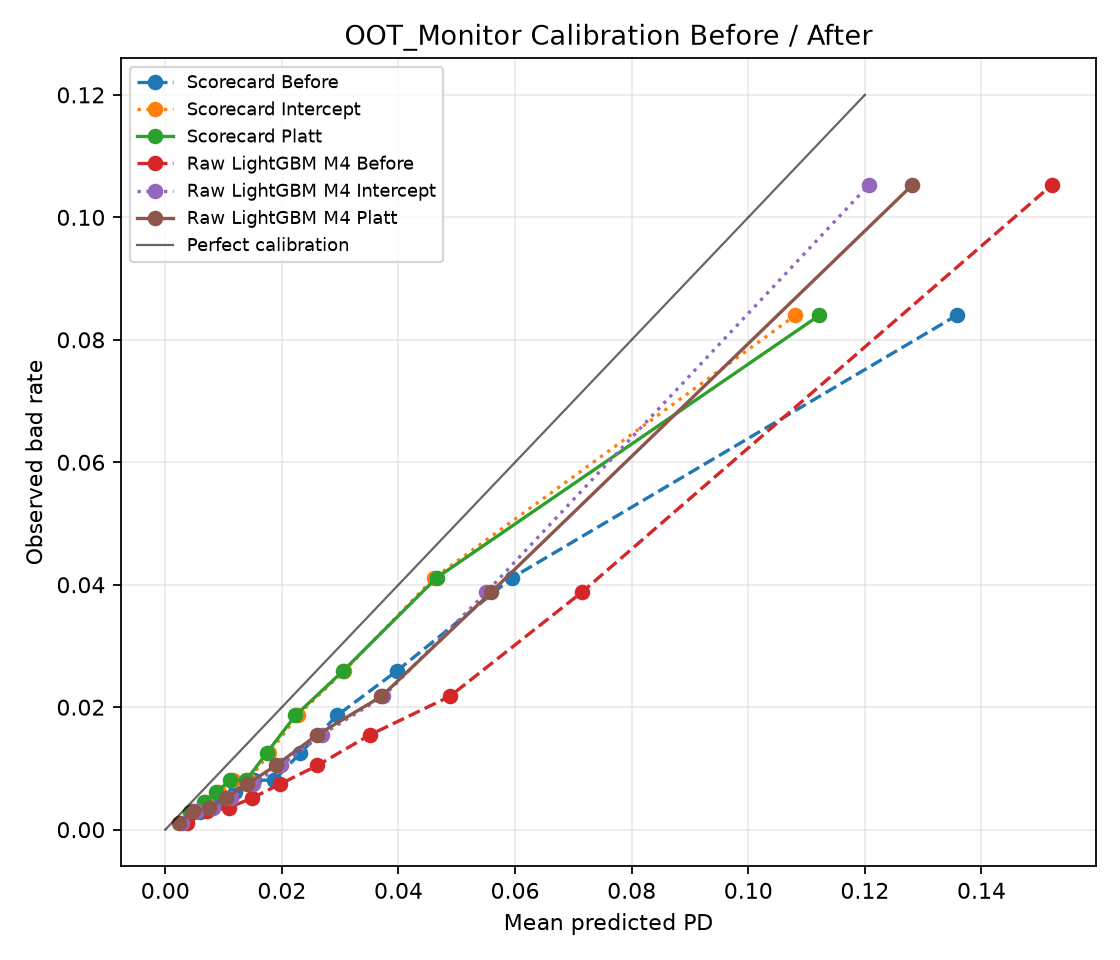

**Saved feature drift diagnostics**

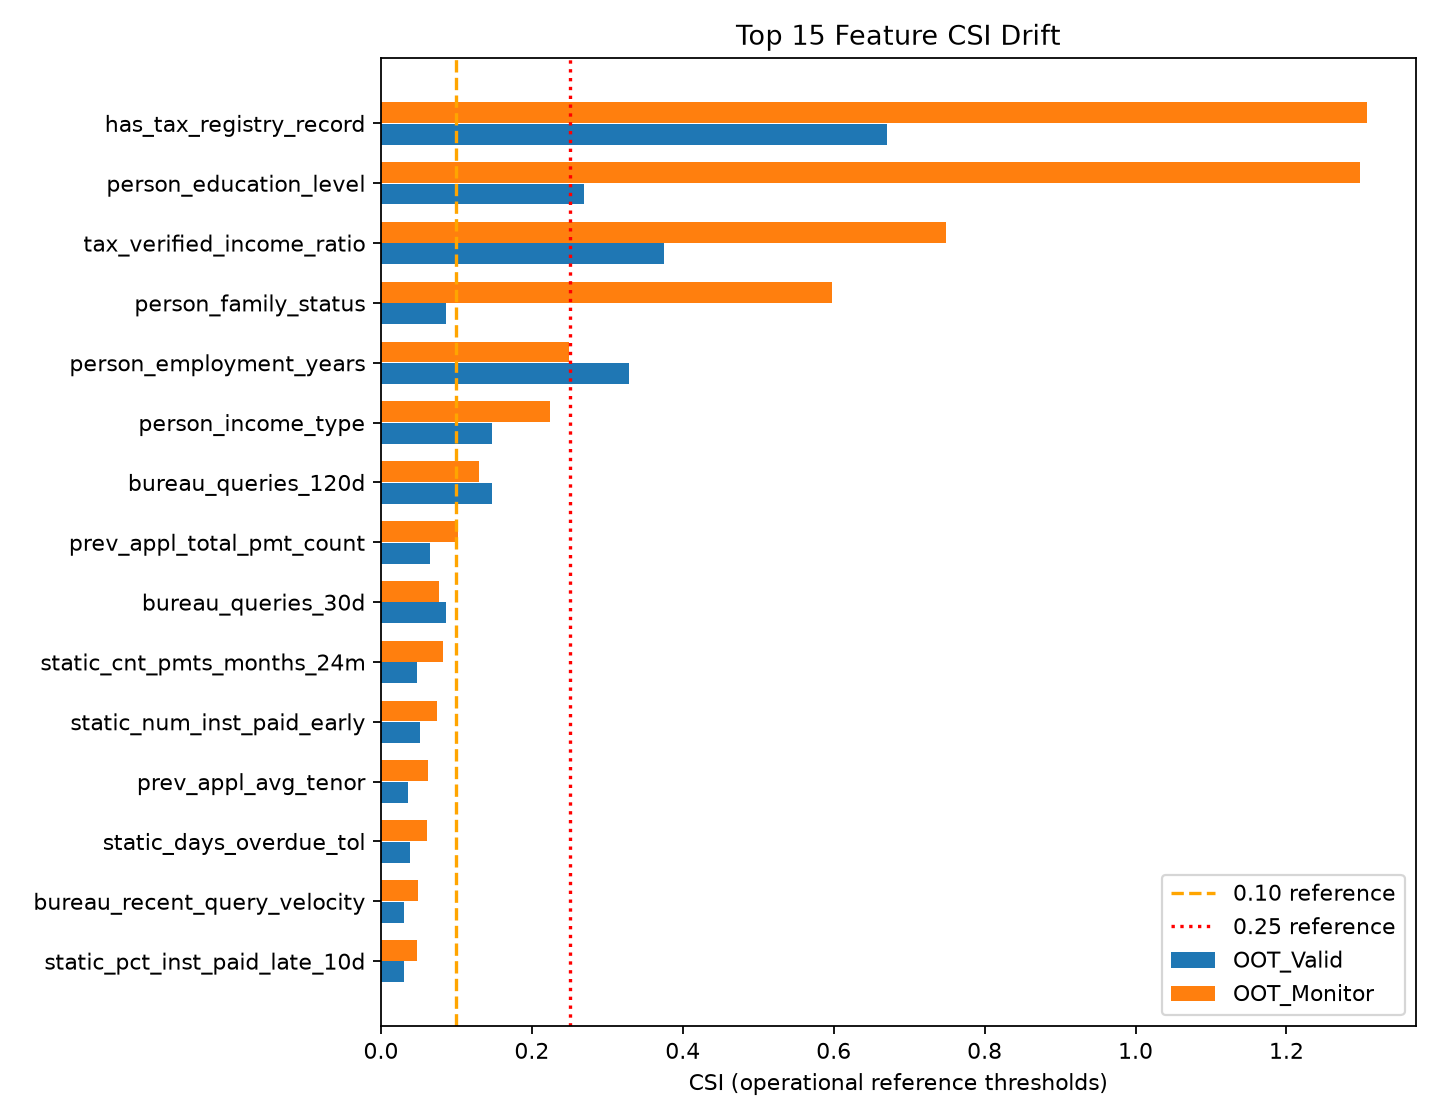

**Saved stress scenario comparison**

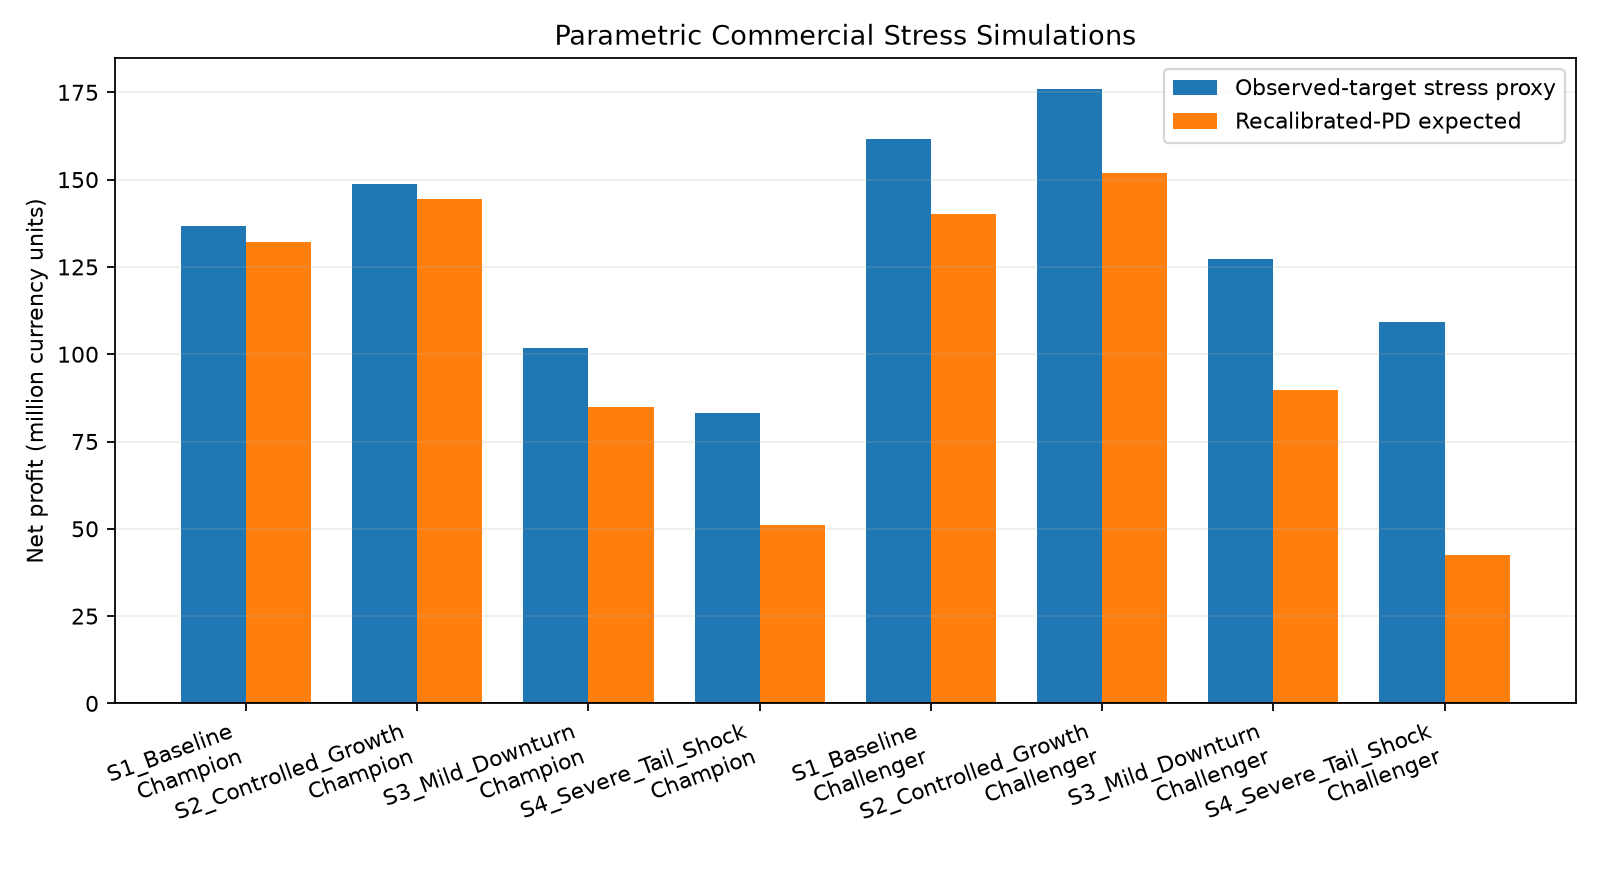

In [6]:
drift = data['drift'].copy()
drift['PSI / CSI'] = pd.to_numeric(drift['PSI / CSI'], errors='coerce')
display(Markdown('**Largest saved PSI/CSI observations:**'))
display(drift.sort_values('PSI / CSI', ascending=False).head(12))

fairness = data['pbi05']
if 'AIR' in fairness:
    fairness_view = fairness.loc[fairness['AIR'].notna()]
    if not fairness_view.empty:
        display(Markdown('**Fair-lending AIR diagnostics:**'))
        display(fairness_view[['Model', 'Split', 'Group', 'Approval_Rate_Pct', 'Observed_Bad_Rate_Pct', 'Mean_Recalibrated_PD_Pct', 'AIR']].head(15))

stress = data['pbi04']
portfolio_stress = stress.loc[stress['Risk_Tier'].eq('Portfolio Total')].copy()
stress_cols = ['Scenario', 'Model', 'Monitor_Approval_Pct', 'Observed_Bad_Rate_Pct', 'Realized_Net_Profit_Stress_Proxy', 'Model_Implied_Expected_Net_Profit']
display(Markdown('**Saved S1–S4 portfolio stress summary:**'))
display(portfolio_stress[stress_cols].sort_values(['Scenario', 'Model']).round(4))

migration = data['pbi06']
display(Markdown('**Prior-DPD severity to current-default migration (selected rows):**'))
display(migration[['Model', 'Risk_Tier', 'Prior_Delinquency_Severity', 'Application_Count', 'Current_Default_Rate_Pct']].head(12))
show_saved_figure('stage5_calibration_before_after.png', 'Saved calibration diagnostics')
show_saved_figure('stage5_top_csi_drift.png', 'Saved feature drift diagnostics')
show_saved_figure('stage6_stress_scenarios.png', 'Saved stress scenario comparison')